# TOPIC 1: Explainable Machine Learning for Gallstone Disease

**Dataset:** UCI Gallstone Disease Dataset (`gallstone-1`)   

## Index of the Notebook

1. **Exploratory Data Analysis (EDA):** Inspect dataset dimensions, feature distributions, missing values, and class balance.
2. **Data Preprocessing:** Separate continuous and binary features, fit `StandardScaler` on continuous features only via `ColumnTransformer`, and perform stratified train/test split ($80/20$).
3. **Model Development & Cross-Validation:** Train 4 classifiers (Logistic Regression, Random Forest, SVM, XGBoost) using 5-Fold Stratified Cross-Validation.
4. **Evaluation:** Compare holdout performance metrics (Accuracy, Precision, Recall, F1-Score, ROC-AUC) and plot confusion matrices.
5. **Model & Scaler Export:** Save top-performing model (`best_model.joblib`) and preprocessor (`scaler.joblib`) to the `dataset/` directory.
6. **Explainability Analysis (XAI - SHAP):** Compute SHAP values, plot global feature importance (Beeswarm & Bar plots), and analyze individual predictions (Waterfall plot).

In [15]:
# NECESSARY LIBRARIES FROM THE COURSE

import os
import warnings
import joblib

# 1.2: Introduction to Python Libraries for Machine Learning
# Data handling, visualization, and preprocessing
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & Model Selection
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 3.2.1 & 3.2.5: Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

# 3.2.3: Evaluation Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report
)

warnings.filterwarnings('ignore')

In [16]:
#uploading the dataset from the location of the excel on the project

#dataset route to the excel
data_path = os.path.join('..', 'dataset', 'dataset-uci.xlsx')

#uploading the dataset with calamine
df = pd.read_excel(data_path, engine='calamine')

#printing to check the succes
print(f"Dataset uploaded. Size: {df.shape}")
df.head()

Dataset uploaded. Size: (319, 39)


,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6


1. **Exploratory Data Analysis (EDA):** Inspect dataset dimensions, feature distributions, and class balance.

Total missing values: 0

Target Class Distribution:
Gallstone Status
0    161
1    158
Name: count, dtype: int64


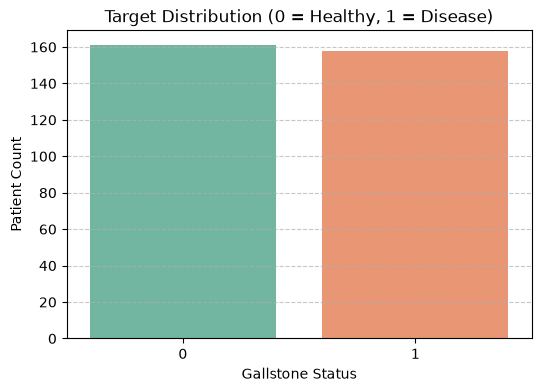

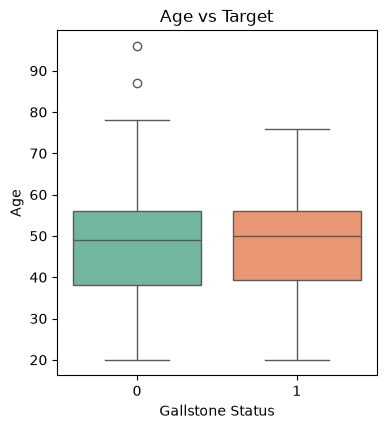

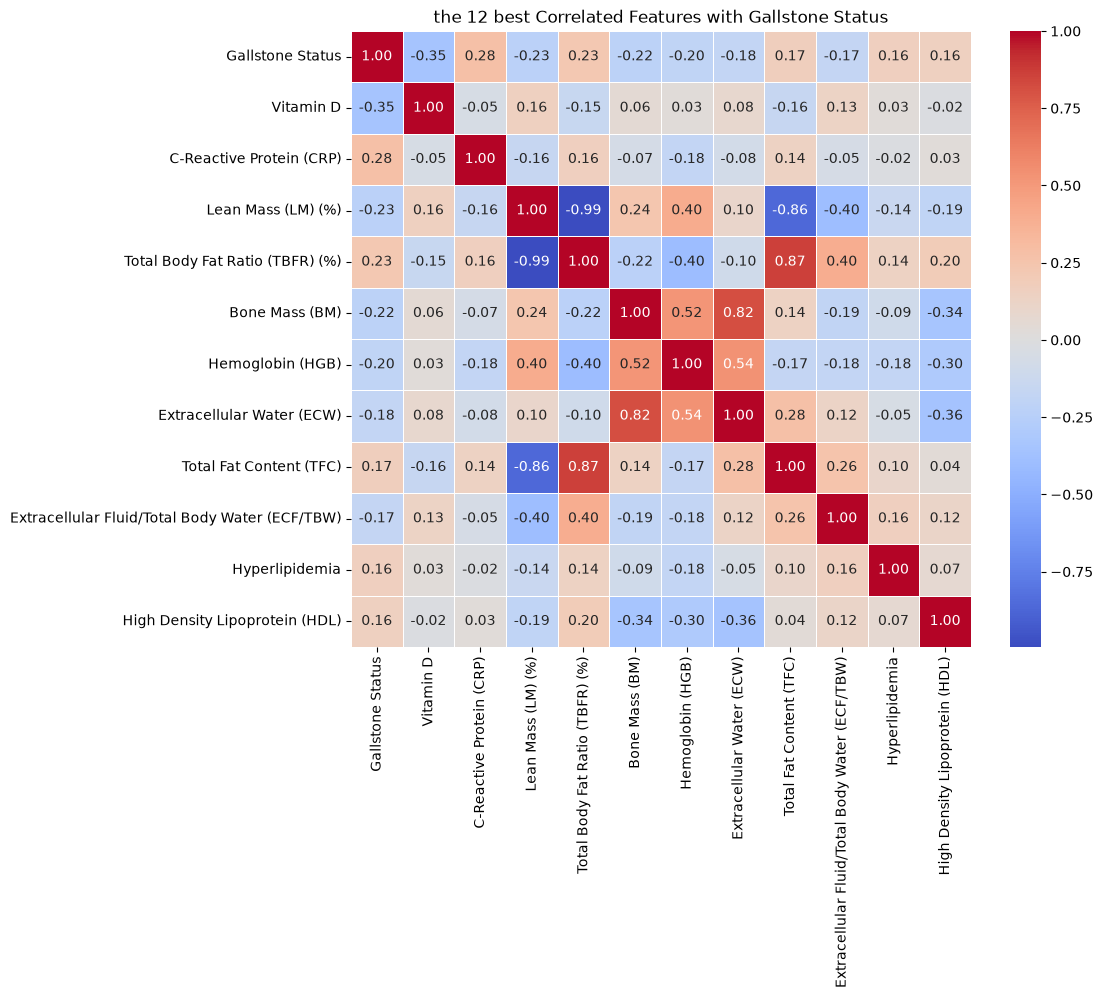

In [17]:
#setting the target
target_col = 'Gallstone Status'

#data Integrity & Missing Values
print(f"Total missing values: {df.isnull().sum().sum()}")

#target Variable Class Balance
print("\nTarget Class Distribution:")
print(df[target_col].value_counts())

#plotting class balance
plt.figure(figsize=(6, 4))
sns.countplot(x=target_col, data=df, hue=target_col, palette='Set2', legend=False)
plt.title('Target Distribution (0 = Healthy, 1 = Disease)')
plt.xlabel('Gallstone Status')
plt.ylabel('Patient Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

#biomarker Distributions through Classes
key_features = ['Age', 'BMI', 'Triglycerides', 'HDL', 'Total Cholesterol', 'ALT', 'AST']
existing_features = [f for f in key_features if f in df.columns]

#plotting the distributions
plt.figure(figsize=(14, 8))
for i, col in enumerate(existing_features, 1):
    plt.subplot(2, 4, i)
    #box graphic
    sns.boxplot(x=target_col, y=col, data=df, palette='Set2', hue=target_col, legend=False)
    plt.title(f'{col} vs Target')
plt.tight_layout()
plt.show()

#Correlation Heatmap (best 12 Features)
plt.figure(figsize=(10, 8))
top_corr_vars = df.corr()[target_col].abs().sort_values(ascending=False).head(12)
sns.heatmap(df[top_corr_vars.index].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('the 12 best Correlated Features with Gallstone Status')
plt.show()

2. **Data Preprocess:** Apply feature scaling and stratified test split ($80/20$).

In [18]:
#separate features and target
X = df.drop(columns=[target_col])
y = df[target_col]

#identify continuous agaisnt binary features
continuous_cols = [c for c in X.columns if X[c].nunique() > 2 and X[c].dtype in ['int64', 'float64']]
binary_cols = [c for c in X.columns if c not in continuous_cols]

#define scales continuous features only
preprocessor = ColumnTransformer(
    transformers=[('num', StandardScaler(), continuous_cols)],
    remainder='passthrough'
)

#stratified Train/Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data preprocessing setup complete:")
print(f" Train set: {X_train.shape[0]} samples")
print(f" Test set:  {X_test.shape[0]} samples")
print(f" Continuous features to scale: {len(continuous_cols)}")
print(f" Binary features preserved:  {len(binary_cols)}")

Data preprocessing setup complete:
 Train set: 255 samples
 Test set:  64 samples
 Continuous features to scale: 33
 Binary features preserved:  5


3. **Model Development:** Train 4 classifiers (Logistic Regression, Random Forest, SVM, XGBoost) with stratified cross-validation.

In [19]:
#dictionary of the different models
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Support Vector Machine': SVC(probability=True, random_state=42),
    'XGBoost': XGBClassifier(eval_metric='logloss', random_state=42)
}

#defining 5-Fold Stratified cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

#list to store the results
cv_results = {}

print("Running 5-Fold Stratified Cross-Validation")
for name, model in models.items():
    #pipeline wraps preprocessing and model to prevent data leakage
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    scores = cross_validate(
        pipeline, X_train, y_train,
        cv=cv, scoring=scoring, return_train_score=False
    )

    #storing the model info
    cv_results[name] = {
        'Accuracy (Mean)': np.mean(scores['test_accuracy']),
        'Precision (Mean)': np.mean(scores['test_precision']),
        'Recall (Mean)': np.mean(scores['test_recall']),
        'F1-Score (Mean)': np.mean(scores['test_f1']),
        'ROC-AUC (Mean)': np.mean(scores['test_roc_auc']),
        'F1-Score (Std)': np.std(scores['test_f1'])
    }

#summary DataFrame sorted by mean F1-Score
cv_summary_df = pd.DataFrame(cv_results).T.sort_values(by='F1-Score (Mean)', ascending=False)
print("\n5-Fold Cross-Validation Results Summary:")
display(cv_summary_df.round(4))

Running 5-Fold Stratified Cross-Validation

5-Fold Cross-Validation Results Summary:


,Accuracy (Mean),Precision (Mean),Recall (Mean),F1-Score (Mean),ROC-AUC (Mean),F1-Score (Std)
Random Forest,0.7529,0.7429,0.7702,0.7555,0.8383,0.0561
XGBoost,0.7490,0.7507,0.7388,0.7431,0.8335,0.0585
Logistic Regression,0.7333,0.7719,0.6594,0.7093,0.8240,0.0549
Support Vector Machine,0.6745,0.6966,0.6342,0.6583,0.7603,0.0583


4. **Evaluation:** Compare performance metrics (Accuracy, Precision, Recall, F1-Score, ROC-AUC) and plot confusion matrices.

In [20]:
#list to store the results
results = []

#looping thorugh the models to seee the different results
for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    #we append the results of the 5 calculated metrics into the list to compare trugh agaisnt predictions
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })

#metrics summary
results_df = pd.DataFrame(results).sort_values(by='F1-Score', ascending=False).reset_index(drop=True)
print("\nModel Performance Summary")
print(results_df.round(4))

#plotting confusion matrix's
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

#looping through the models and plotting the confusion matrix
for idx, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(f'{name}')
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')

#plotting the results of the confusion matrix
plt.tight_layout()
plt.show()

NotFittedError: This LogisticRegression instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.

5. **Model Export:** Save the top-performing model (`best_model.joblib`) to the `dataset/` directory for SHAP/LIME explainability analysis.

In [ ]:
#seeing which one is the top-performing model based on the highest F1-Score
best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]

#define the output path in dataset/ directory
best_model_path = os.path.join('..', 'dataset', 'best_model.joblib')

#saving model binary using joblib
joblib.dump(best_model, best_model_path)

#printing the results
print(f"\n Best Model: '{best_model_name}' (F1-Score: {results_df.iloc[0]['F1-Score']:.4f})")
print(f"Model successfully exported to: {best_model_path} for SHAP analysis.")


 Best Model: 'XGBoost' (F1-Score: 0.8475)
Model successfully exported to: ..\dataset\best_model.joblib for SHAP analysis.
